# Phase 1: Data Audit & Risk Evaluation

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler

In [29]:
df = pd.read_csv("ai4i2020.csv")

## Initial dataset overview

In [30]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [31]:
df_raw = df.copy()

df = df.rename(columns={
    'Air temperature [K]': 'air_temp',
    'Process temperature [K]': 'process_temp',
    'Rotational speed [rpm]': 'rot_speed',
    'Torque [Nm]': 'torque',
    'Tool wear [min]': 'tool_wear',
    'Machine failure': 'machine_failure',
    'Product ID': 'product_id',
    'Type': 'type'
})

numeric_cols = ['air_temp', 'process_temp', 'rot_speed', 'torque', 'tool_wear']
failure_cols = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   UDI              10000 non-null  int64  
 1   product_id       10000 non-null  str    
 2   type             10000 non-null  str    
 3   air_temp         10000 non-null  float64
 4   process_temp     10000 non-null  float64
 5   rot_speed        10000 non-null  int64  
 6   torque           10000 non-null  float64
 7   tool_wear        10000 non-null  int64  
 8   machine_failure  10000 non-null  int64  
 9   TWF              10000 non-null  int64  
 10  HDF              10000 non-null  int64  
 11  PWF              10000 non-null  int64  
 12  OSF              10000 non-null  int64  
 13  RNF              10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
memory usage: 1.1 MB


In [33]:
df.isnull().sum()

UDI                0
product_id         0
type               0
air_temp           0
process_temp       0
rot_speed          0
torque             0
tool_wear          0
machine_failure    0
TWF                0
HDF                0
PWF                0
OSF                0
RNF                0
dtype: int64

In [34]:
df.describe().round(2)

,UDI,air_temp,process_temp,rot_speed,torque,tool_wear,machine_failure,TWF,HDF,PWF,OSF,RNF
count,10000.00,10000.0,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,5000.50,300.0,310.01,1538.78,39.99,107.95,0.03,0.00,0.01,0.01,0.01,0.00
std,2886.90,2.0,1.48,179.28,9.97,63.65,0.18,0.07,0.11,0.10,0.10,0.04
min,1.00,295.3,305.70,1168.00,3.80,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2500.75,298.3,308.80,1423.00,33.20,53.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,5000.50,300.1,310.10,1503.00,40.10,108.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,7500.25,301.5,311.10,1612.00,46.80,162.00,0.00,0.00,0.00,0.00,0.00,0.00
max,10000.00,304.5,313.80,2886.00,76.60,253.00,1.00,1.00,1.00,1.00,1.00,1.00


In [35]:
print((df['air_temp'] <= 0).sum())
print((df['process_temp'] <= 0).sum())
print((df['rot_speed'] < 0).sum())
print((df['torque'] < 0).sum())
print((df['tool_wear'] < 0).sum())

0
0
0
0
0


In [36]:
print(df.duplicated().sum())

0


In [37]:
any_mode_flag = df[failure_cols].sum(axis=1) > 0

inconsistent_a = df[(df['machine_failure'] == 1) & (~any_mode_flag)]
inconsistent_b = df[(df['machine_failure'] == 0) & (any_mode_flag)]

print(f"machine_failure=1 but no mode flag set: {len(inconsistent_a)}")
print(f"machine_failure=0 but a mode flag is set: {len(inconsistent_b)}")

multi_mode = df[df[failure_cols].sum(axis=1) > 1]
print(f"Records with more than one failure mode flagged simultaneously: {len(multi_mode)}")

machine_failure=1 but no mode flag set: 9
machine_failure=0 but a mode flag is set: 18
Records with more than one failure mode flagged simultaneously: 24


* This dataset has no missing values
* All numerical values are within realistic physical bounds.
* There are 0 duplicate records.
* Any row where `machine_failure=0` but a mode flag (TWF/HDF/PWF/OSF/RNF) is set to 1 (or vice-versa) means the label a model would learn from is unreliable — a control system trained on this could miss real failures or raise false alarms.

# Phase 2: Sensor Behavior Analysis

In [38]:
dist_summary = df[numeric_cols].describe().T
dist_summary['IQR'] = dist_summary['75%'] - dist_summary['25%']
dist_summary['skew'] = df[numeric_cols].skew()
dist_summary.round(2)

,count,mean,std,min,25%,50%,75%,max,IQR,skew
air_temp,10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5,3.2,0.11
process_temp,10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8,2.3,0.02
rot_speed,10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0,189.0,1.99
torque,10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6,13.6,-0.01
tool_wear,10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0,109.0,0.03


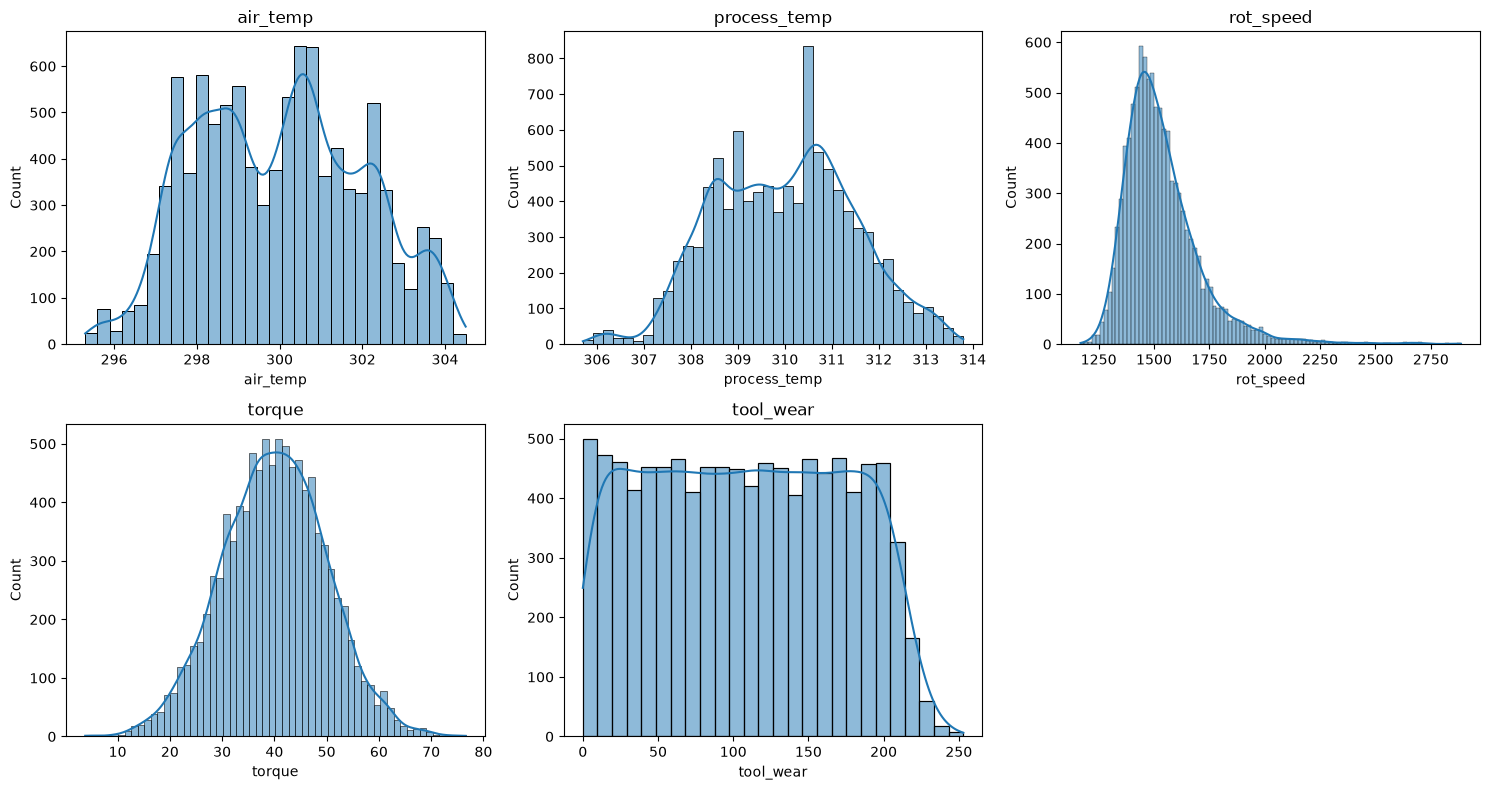

In [39]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

In [40]:
extreme_zones = pd.DataFrame({
    'p01': df[numeric_cols].quantile(0.01),
    'p99': df[numeric_cols].quantile(0.99),
    'count_below_p01': (df[numeric_cols] < df[numeric_cols].quantile(0.01)).sum(),
    'count_above_p99': (df[numeric_cols] > df[numeric_cols].quantile(0.99)).sum(),
})
extreme_zones

,p01,p99,count_below_p01,count_above_p99
air_temp,295.9,304.10,99,63
process_temp,306.6,313.20,98,97
rot_speed,1275.0,2188.01,98,100
torque,16.7,62.80,99,99
tool_wear,0.0,222.00,0,99


In [41]:
df.groupby('machine_failure')[numeric_cols].agg(['mean', 'std'])

air_temp           process_temp              rot_speed  \
                       mean       std         mean       std         mean   
machine_failure                                                             
0                299.973999  1.990748   309.995570  1.486846  1540.260014   
1                300.886431  2.071473   310.290265  1.363686  1496.486726   

                                torque              tool_wear             
                        std       mean        std        mean        std  
machine_failure                                                           
0                167.394734  39.629655   9.472080  106.693717  62.945790  
1                384.943547  50.168142  16.374498  143.781711  72.759876

**Normal vs. failed machines** — comparison of each sensor's central tendency and spread between `machine_failure == 0` and `machine_failure == 1`.

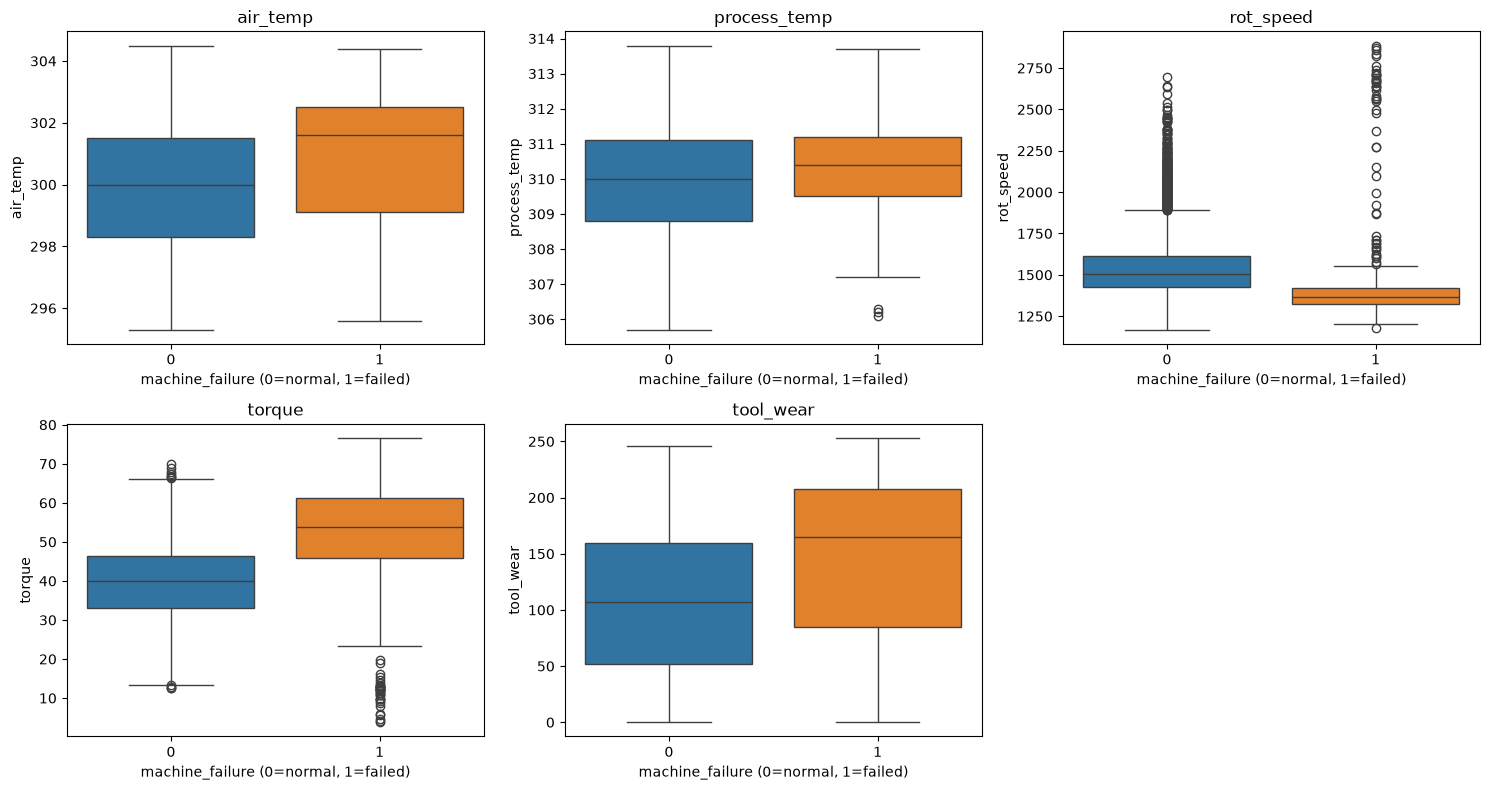

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(data=df, x='machine_failure', y=col, ax=ax, hue='machine_failure', legend=False)
    ax.set_title(col)
    ax.set_xlabel('machine_failure (0=normal, 1=failed)')
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

### Which sensors behave differently before failure?
Torque, Air Temperature and Tool Wear means increased after failure, Rotational Speed decreased. From the grouped table: `air_temp` rises only slightly (≈299.97 K → 300.89 K) and `process_temp` barely moves (≈309.996 K → 310.29 K), so temperature alone is a weak separator. `rot_speed` is more telling because its mean drops (≈1540 → 1496 rpm) but its std more than doubles (≈167 → 385), meaning speed becomes far less stable before failure, not just slower on average.
### Which variables may be early warning signals?
`tool_wear` is a natural early-warning candidate because it increases monotonically over a tool's life  a rising trend, rather than a single threshold, is the true signal (its distribution is fairly symmetric, skew≈0.03, with a wide IQR of 109 minutes). `rot_speed` is a second candidate precisely because of its instability before failure (std nearly tripling) rather than its average value  and it also has the heaviest right tail of all sensors (skew≈1.99, p99=2188 rpm vs. a max of 2886 rpm), so sudden high-speed excursions are worth flagging on their own.

# PHASE 3: Industrial Anomaly Detection

In [43]:
def zscore_outliers(series):
    z = np.abs(stats.zscore(series))
    return z > 3

def iqr_outliers(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (series < lower) | (series > upper)

z_flags = pd.DataFrame({col: zscore_outliers(df[col]) for col in numeric_cols})
iqr_flags = pd.DataFrame({col: iqr_outliers(df[col]) for col in numeric_cols})

df['anomaly_zscore'] = z_flags.any(axis=1)
df['anomaly_iqr'] = iqr_flags.any(axis=1)

print(f"Z-score anomalies: {df['anomaly_zscore'].sum()}")
print(f"IQR anomalies:     {df['anomaly_iqr'].sum()}")
print(f"Both methods:      {(df['anomaly_zscore'] & df['anomaly_iqr']).sum()}")

Z-score anomalies: 178
IQR anomalies:     459
Both methods:      178


In [44]:
def failure_rate_by_flag(flag_col):
    return df.groupby(flag_col)['machine_failure'].mean().rename('failure_rate')

overall_rate = df['machine_failure'].mean()
print(f"Overall failure rate: {overall_rate:.4f}\n")

print("By Z-score anomaly flag:")
print(failure_rate_by_flag('anomaly_zscore'))
print("\nBy IQR anomaly flag:")
print(failure_rate_by_flag('anomaly_iqr'))

Overall failure rate: 0.0339

By Z-score anomaly flag:
anomaly_zscore
False    0.029831
True     0.258427
Name: failure_rate, dtype: float64

By IQR anomaly flag:
anomaly_iqr
False    0.027984
True     0.156863
Name: failure_rate, dtype: float64


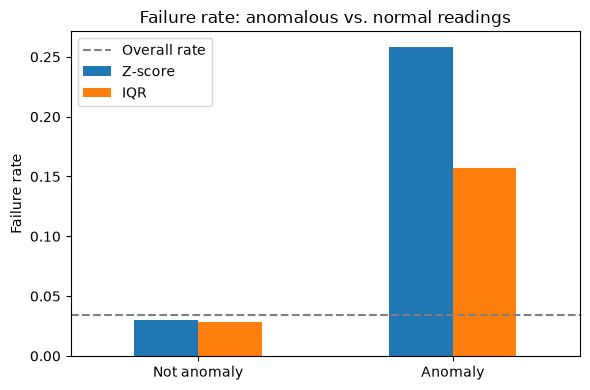

In [45]:
fig, ax = plt.subplots(figsize=(6, 4))
rates = pd.DataFrame({
    'Z-score': failure_rate_by_flag('anomaly_zscore'),
    'IQR': failure_rate_by_flag('anomaly_iqr')
})
rates.index = ['Not anomaly', 'Anomaly']
rates.plot(kind='bar', ax=ax)
ax.axhline(overall_rate, color='gray', linestyle='--', label='Overall rate')
ax.set_ylabel('Failure rate')
ax.set_title('Failure rate: anomalous vs. normal readings')
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Are anomalies noise or early breakdown signals?   
Z-score flags **178** rows and IQR flags **459** rows, and all 178 Z-score anomalies are a subset of the IQR ones. The failure rate jumps from the 3.39% baseline to **25.84%** inside the Z-score-flagged group and **15.69%** inside the IQR-flagged group (7–8x higher than normal). That gap is far too large to be random noise, so the anomalies are not random noise — they are correlated with breakdowns and carry real signal.

### Should we remove them or mark them as risk indicators?
We should mark anomalies as risk indicators. In this domain, "outliers" are frequently the exact operating conditions that precede failure (e.g. a torque or tool-wear spike right before breakdown). Deleting them would remove the very signal a predictive-maintenance model needs. The failure-rate comparison above shows anomalous readings fail at a different rate than normal ones, confirming they are informative rather than pure measurement noise.

# PHASE 4: Risk Segmentation (Business-Oriented)

In [46]:
df['temp_diff'] = df['process_temp'] - df['air_temp']

df['tool_wear_risk'] = pd.cut(
    df['tool_wear'], bins=[-0.1, 100, 200, df['tool_wear'].max()],
    labels=['Normal', 'Maintenance soon', 'Critical']
)

t1, t2 = df['temp_diff'].quantile([1/3, 2/3])
df['temp_diff_risk'] = pd.cut(
    df['temp_diff'], bins=[-np.inf, t1, t2, np.inf],
    labels=['Stable', 'Warning', 'Overheating risk']
)

print(f"Temp diff tertile cut points: {t1:.2f} K, {t2:.2f} K\n")
df[['tool_wear', 'tool_wear_risk', 'temp_diff', 'temp_diff_risk']].head()

Temp diff tertile cut points: 9.40 K, 10.70 K



,tool_wear,tool_wear_risk,temp_diff,temp_diff_risk
0,0,Normal,10.5,Warning
1,3,Normal,10.5,Warning
2,5,Normal,10.4,Warning
3,7,Normal,10.4,Warning
4,9,Normal,10.5,Warning


Failure rate per risk zone

In [47]:
tool_wear_table = df.groupby('tool_wear_risk', observed=True).agg(
    n_records=('machine_failure', 'size'),
    failure_rate=('machine_failure', 'mean')
)
temp_diff_table = df.groupby('temp_diff_risk', observed=True).agg(
    n_records=('machine_failure', 'size'),
    failure_rate=('machine_failure', 'mean')
)

print("Tool wear risk zones:")
display(tool_wear_table)
print("\nTemperature-difference risk zones:")
display(temp_diff_table)

Tool wear risk zones:


,n_records,failure_rate
tool_wear_risk,,
Normal,4667,0.022498
Maintenance soon,4571,0.025377
Critical,762,0.154856



Temperature-difference risk zones:


,n_records,failure_rate
temp_diff_risk,,
Stable,3430,0.055394
Warning,3295,0.023065
Overheating risk,3275,0.022290


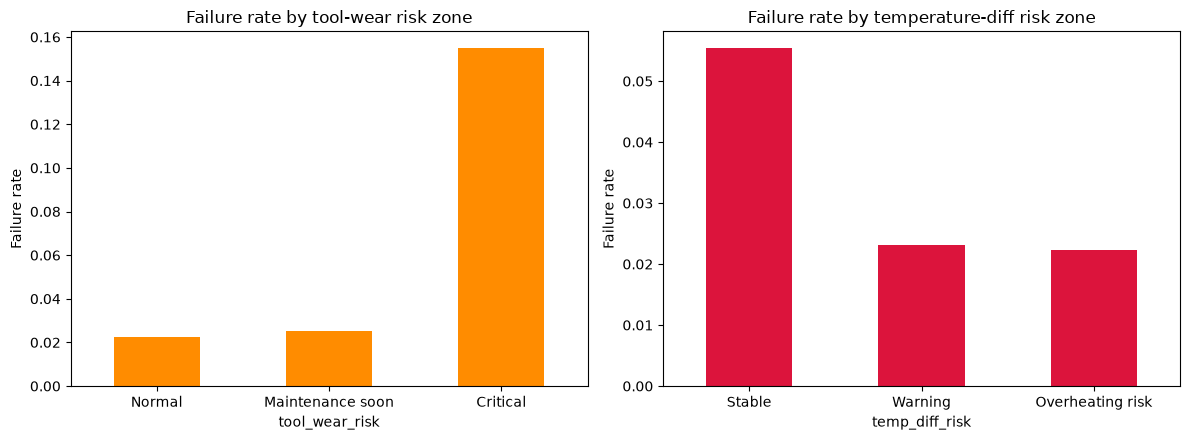

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
tool_wear_table['failure_rate'].plot(kind='bar', ax=axes[0], color='darkorange')
axes[0].set_title('Failure rate by tool-wear risk zone')
axes[0].set_ylabel('Failure rate')
axes[0].tick_params(axis='x', rotation=0)

temp_diff_table['failure_rate'].plot(kind='bar', ax=axes[1], color='crimson')
axes[1].set_title('Failure rate by temperature-diff risk zone')
axes[1].set_ylabel('Failure rate')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## Does risk segmentation meaningfully separate failure probability?

**Tool wear: yes, clearly.** The Critical zone (762 records, wear > 200 min) has a **15.49%** failure rate vs. **2.25%** (Normal) and **2.54%** (Maintenance soon) — roughly 6–7x higher risk. This segmentation is business-ready as-is.

**Temperature difference: separates risk, but in the opposite direction the labels imply.** The *Stable* zone (small process−air gap, 3430 records) actually has the *highest* failure rate (**5.54%**), while *Warning* (2.31%) and *Overheating risk* (2.23%) are lower. This lines up with how this dataset's Heat Dissipation Failure is defined — it triggers specifically when the temperature gap is *small* combined with low rotational speed, so a small gap is the genuinely risky condition here, not a large one. The segmentation itself is meaningful, but the zone **names should be corrected** (e.g. relabel "Stable" as the highest-risk zone) before this table goes to operations, or maintenance staff will watch the wrong machines.

# PHASE 5: Data Preparation for Production

We use **StandardScaler** (zero mean, unit variance) rather than min-max scaling.     
The Phase 2 distributions are roughly unimodal and not bounded to a fixed physical range in a way that favors [0,1] scaling, several features (e.g. `rot_speed`, `torque`) have mild skew and occasional extreme values (Phase 3), and standardization is far less sensitive to those extreme values than min-max scaling, which would let a single extreme point compress the rest of the data into a tiny range. Standard scaling is also the conventional default for the distance- and gradient-based models (e.g. logistic regression, SVM, neural nets) typically used downstream for failure prediction.

In [49]:
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[numeric_cols] = scaler.fit_transform(df[numeric_cols])

df_scaled[numeric_cols].describe().loc[['mean', 'std']].round(3)

,air_temp,process_temp,rot_speed,torque,tool_wear
mean,-0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


Class imbalance check

machine_failure
0    9661
1     339
Name: count, dtype: int64

machine_failure
0    96.61 %
1     3.39 %
Name: proportion, dtype: str


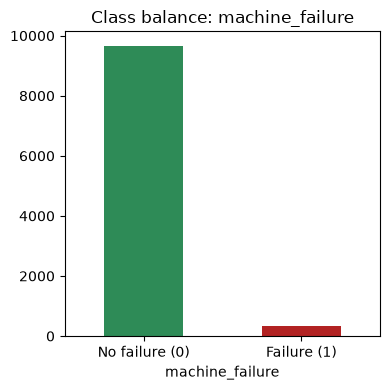

In [50]:
imbalance = df['machine_failure'].value_counts()
imbalance_pct = df['machine_failure'].value_counts(normalize=True) * 100

print(imbalance)
print()
print(imbalance_pct.round(2).astype(str) + ' %')

fig, ax = plt.subplots(figsize=(4, 4))
imbalance.plot(kind='bar', ax=ax, color=['seagreen', 'firebrick'])
ax.set_xticklabels(['No failure (0)', 'Failure (1)'], rotation=0)
ax.set_title('Class balance: machine_failure')
plt.tight_layout()
plt.show()

We use a **stratified** 30% sample so the already-rare failure class isn't further diluted or, worse, distorted by chance. This keeps the sample representative of the true failure rate, which matters for any evaluation done on it later.

In [51]:
from sklearn.model_selection import train_test_split

sample_df, _ = train_test_split(
    df, train_size=0.30, stratify=df['machine_failure'], random_state=42
)

print(f"Full dataset size:   {len(df)}")
print(f"30% sample size:     {len(sample_df)}")
print(f"Full failure rate:   {df['machine_failure'].mean():.4f}")
print(f"Sample failure rate: {sample_df['machine_failure'].mean():.4f}")

Full dataset size:   10000
30% sample size:     3000
Full failure rate:   0.0339
Sample failure rate: 0.0340


Compare sample vs. full dataset statistics

In [52]:
compare_stats = pd.concat(
    {
        'full': df[numeric_cols].describe().loc[['mean', 'std', 'min', 'max']],
        'sample_30pct': sample_df[numeric_cols].describe().loc[['mean', 'std', 'min', 'max']],
    },
    axis=1
)
compare_stats

full                                                   \
        air_temp process_temp    rot_speed     torque   tool_wear   
mean  300.004930   310.005560  1538.776100  39.986910  107.951000   
std     2.000259     1.483734   179.284096   9.968934   63.654147   
min   295.300000   305.700000  1168.000000   3.800000    0.000000   
max   304.500000   313.800000  2886.000000  76.600000  253.000000   

     sample_30pct                                                  
         air_temp process_temp   rot_speed     torque   tool_wear  
mean   300.029533   310.023467  1537.61900  40.040200  107.250333  
std      2.000209     1.465971   180.21641   9.929227   63.734070  
min    295.500000   305.900000  1168.00000   3.800000    0.000000  
max    304.500000   313.800000  2886.00000  75.400000  244.000000

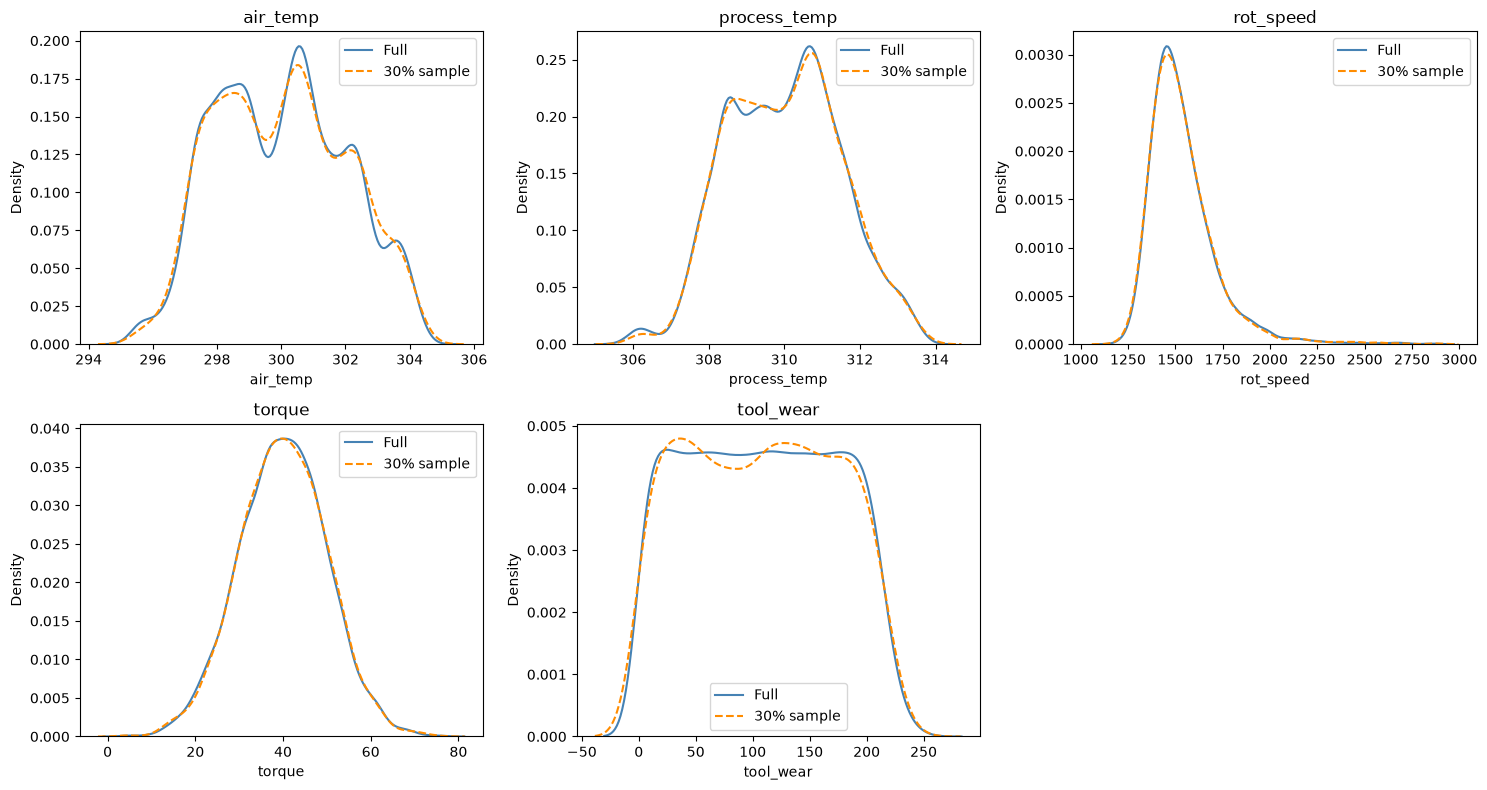

In [53]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.kdeplot(df[col], ax=ax, label='Full', color='steelblue')
    sns.kdeplot(sample_df[col], ax=ax, label='30% sample', color='darkorange', linestyle='--')
    ax.set_title(col)
    ax.legend()
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

### Question: If this dataset is used for model training, what bias risks exist?

- **Severe class imbalance** means a model can reach high accuracy by predicting "no failure"
- **Sampling bias:** even a stratified 30% sample can under-represent rare failure *sub-types* (e.g. one of TWF/HDF/PWF/OSF/RNF) if that mode is already rare in the full data
- **Label bias:** the Phase 1 inconsistent-flag records mean a small fraction of training labels may be wrong, which biases the model toward whatever pattern those mislabeled rows have in common.
- **Anomaly-informed features:** since Phase 3 kept anomalies rather than removing them, a model trained without also including the `anomaly_zscore` / `anomaly_iqr` features may miss the exact signal that distinguishes real breakdowns from routine noise, while a model trained with them needs to be checked for leakage
- **Scaler leakage risk:** the `StandardScaler` above was fit on the full dataset for demonstration; in a real production pipeline it must be fit only on the training split and then applied to validation/test/sample data, or statistics from the future/held-out data will leak into training.